# Buổi G5: Khoảng dự đoán, không chỉ một con số mà cả mức lệch

**Hiện trường.** Mô hình báo "tuần sau bán 120 hộp sữa". Chị Hạnh nhập đúng 120 hộp, nhưng có tuần bán 90 (ế), có tuần bán 170 (hết hàng, mất khách). Điều chị cần không phải một con số, mà là **một khoảng**: "có 80% khả năng bán từ 95 đến 150 hộp".

Buổi này dạy cách dự đoán **khoảng**:
- **Hồi quy phân vị** (*quantile regression*): thay vì đoán trung bình, đoán thẳng "mức mà 10% số lần thấp hơn" và "mức mà 90% số lần thấp hơn".
- **Kiểm tra độ phủ** (*coverage*): khoảng nói 80% thì thực tế có phủ 80% không.
- **Hiệu chỉnh bằng conformal**: dùng một tập riêng để ép khoảng phủ đúng mức hứa.

**Ẩn dụ:** dự báo thời tiết "mai mưa 70%" hữu ích hơn "mai có mưa" vì bạn tự quyết định mang ô hay không. Khoảng dự đoán cũng vậy: người ra quyết định tự chọn mức an toàn.

**Mindset của người làm dữ liệu:** khoảng chỉ có giá trị khi **kiểm được**. Một khoảng "80%" mà thực tế phủ 60% là lời hứa suông.

**Lưu ý:** dữ liệu dựng có chủ đích (mức dao động tăng theo quy mô); dùng để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: đường trung bình và dải 10% đến 90% |
| Chặng 1 | Hàm mất mát pinball: vì sao nó cho ra phân vị |
| Chặng 2 | Kiểm độ phủ: tổng thể và theo từng vùng |
| Chặng 3 | Mô hình tuyến tính hay cây cho phân vị |
| Chặng 4 | Conformal: ép khoảng phủ đúng mức hứa |
| Chặng 5 | Dùng cho quyết định: đặt hàng bao nhiêu |

## Chặng 0: Thấy ngay, dải 10% đến 90%

**Câu hỏi:** khi mức dao động tăng theo quy mô, một đường trung bình có đủ không?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

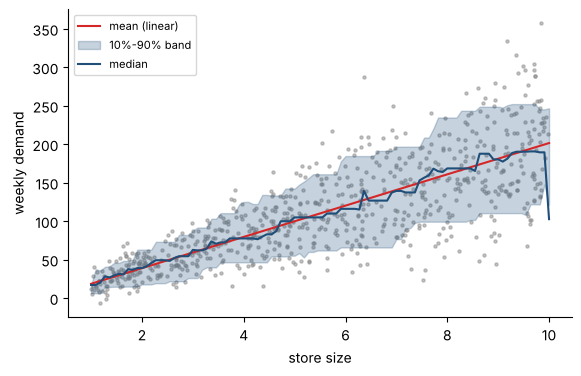

band width at size 1.5: 31.1 | at size 9: 138.4
rows -> train 1500 | calibration 750 | test 750


In [2]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
rng = np.random.RandomState(0)
n = 3000
size = rng.uniform(1, 10, n)
demand = 20 * size + rng.normal(0, 1, n) * (4 + 6 * size)
df = pd.DataFrame({"size": size})
X_tr, X_rest, y_tr, y_rest = train_test_split(df, demand, test_size=0.5, random_state=0)
X_cal, X_te, y_cal, y_te = train_test_split(X_rest, y_rest, test_size=0.5, random_state=0)
mean_m = LinearRegression().fit(X_tr, y_tr)
q = {a: GradientBoostingRegressor(loss="quantile", alpha=a, n_estimators=150, max_depth=2, learning_rate=0.1, random_state=0).fit(X_tr, y_tr) for a in (0.1, 0.5, 0.9)}
xs = pd.DataFrame({"size": np.linspace(1, 10, 100)})
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(X_te["size"], y_te, s=5, color=GRAY, alpha=0.5)
ax.plot(xs["size"], mean_m.predict(xs), color="tab:red", label="mean (linear)")
ax.fill_between(xs["size"], q[0.1].predict(xs), q[0.9].predict(xs), color=BLUE, alpha=0.25, label="10%-90% band")
ax.plot(xs["size"], q[0.5].predict(xs), color=BLUE, label="median")
ax.set_xlabel("store size"); ax.set_ylabel("weekly demand"); ax.legend(fontsize=8); plt.show()
w_small = float((q[0.9].predict(pd.DataFrame({"size": [1.5]})) - q[0.1].predict(pd.DataFrame({"size": [1.5]})))[0])
w_big = float((q[0.9].predict(pd.DataFrame({"size": [9.0]})) - q[0.1].predict(pd.DataFrame({"size": [9.0]})))[0])
print("band width at size 1.5:", round(w_small, 1), "| at size 9:", round(w_big, 1))
print("rows -> train", len(X_tr), "| calibration", len(X_cal), "| test", len(X_te))

**Giải thích từng dòng**

- `rng.normal(0, 1, n) * (4 + 6 * size)`: mức dao động **tăng theo quy mô**: cửa hàng nhỏ ổn định, cửa hàng lớn thất thường. Dữ liệu dựng có chủ đích.
- `train_test_split(...) hai lần`: chia ba phần: **học** (huấn luyện), **hiệu chỉnh** (chặng 4) và **thi** (kiểm độ phủ).
- `GradientBoostingRegressor(loss="quantile", alpha=a)`: cây tăng cường (E3) nhưng huấn luyện với hàm mất mát phân vị: `alpha=0.1` đoán mức mà **10%** số lần thấp hơn, `alpha=0.9` đoán mức mà **90%** thấp hơn. Khoảng giữa hai mức chứa khoảng 80% số lần.
- `fill_between(q10, q90)`: tô dải giữa hai phân vị.

**Cách đọc.**
- **Con số:** bề rộng dải 10% đến 90% là **31,1** ở cửa hàng cỡ 1,5 và **138,4** ở cỡ 9.
- **Bức tranh:** đường đỏ (trung bình) chỉ cho một con số; dải xanh **loe ra** theo quy mô, đúng như dữ liệu. Một khoảng cố định (cộng trừ cùng một biên) sẽ quá rộng cho cửa hàng nhỏ và quá hẹp cho cửa hàng lớn.
- **Câu hỏi tiếp:** vì sao huấn luyện với `loss="quantile"` lại ra được phân vị?

**Mang về chặng 1:** phân vị cho khoảng thích ứng với mức dao động từng vùng.

## Chặng 1: Hàm mất mát pinball

**Câu hỏi:** sai số nào làm máy tự tìm ra phân vị?

In [3]:
def pinball(y_true, pred, a):
    diff = y_true - pred
    return np.mean(np.maximum(a * diff, (a - 1) * diff))
sample = rng.lognormal(3, 0.6, 5000)
grid = np.linspace(sample.min(), np.percentile(sample, 99.5), 800)
rows = []
for a in (0.1, 0.5, 0.9):
    losses = [pinball(sample, c, a) for c in grid]
    rows.append({"alpha": a, "best constant by pinball": round(float(grid[int(np.argmin(losses))]), 2), "np.quantile": round(float(np.quantile(sample, a)), 2), "mean": round(float(sample.mean()), 2)})
pin_table = pd.DataFrame(rows).set_index("alpha")
print(pin_table.to_string())

       best constant by pinball  np.quantile   mean
alpha                                              
0.1                        9.31         9.28  23.75
0.5                       19.81        19.81  23.75
0.9                       42.55        42.55  23.75


**Giải thích từng dòng**

- `diff = y_true - pred`: sai số có dấu: dương nghĩa là đoán thấp hơn thực tế, âm là đoán cao hơn.
- `np.maximum(a * diff, (a - 1) * diff)`: **pinball loss**: đoán thấp bị phạt `a` mỗi đơn vị, đoán cao bị phạt `1 - a` mỗi đơn vị. Với `a = 0.9`, đoán thấp bị phạt nặng gấp 9 lần đoán cao, nên máy tự đẩy dự đoán lên cao.
- `np.argmin(losses)`: trong các hằng số thử, chọn hằng số làm tổng phạt nhỏ nhất.

**Cách đọc.**
- **Con số:** với `a = 0,9`, hằng số tốt nhất theo pinball là **42,55**, trùng với phân vị 90% của dữ liệu (**42,55**), còn trung bình là **23,75**.
- **Bức tranh:** bình phương sai số (B2) cho ra **trung bình**; trị tuyệt đối đối xứng (`a = 0,5`) cho ra **trung vị**; phạt lệch hai phía cho ra **phân vị bất kỳ**. Chọn hàm mất mát nào là chọn mô hình trả lời câu hỏi nào.
- **Câu hỏi tiếp:** khoảng 10% đến 90% có thật sự phủ 80% số lần không?

**Mang về chặng 2:** mất mát pinball đối xứng cho trung vị, lệch về phía nào thì ra phân vị phía đó.

## Chặng 2: Kiểm độ phủ

**Câu hỏi:** khoảng "80%" có thật sự chứa 80% các lần thi?

In [4]:
lo, hi = q[0.1].predict(X_te), q[0.9].predict(X_te)
inside = (y_te >= lo) & (y_te <= hi)
coverage_all = float(inside.mean())
bins = pd.cut(X_te["size"].to_numpy(), [1, 3, 5, 7, 10])
cov_by = pd.Series(inside).groupby(bins, observed=True).mean().round(3)
# constant-width interval around the linear mean (width from training residuals)
res = y_tr - mean_m.predict(X_tr)
half = np.quantile(np.abs(res), 0.8)
inside_c = np.abs(y_te - mean_m.predict(X_te)) <= half
cov_c = pd.Series(inside_c).groupby(bins, observed=True).mean().round(3)
print("quantile band coverage overall:", round(coverage_all, 3), "| fixed-width band overall:", round(float(inside_c.mean()), 3))
print(pd.DataFrame({"quantile band": cov_by.values, "fixed-width band": cov_c.values}, index=[str(i) for i in cov_by.index]).to_string())
print("average width: quantile band", round(float((hi - lo).mean()), 1), "| fixed-width band", round(2 * float(half), 1))

quantile band coverage overall: 0.777 | fixed-width band overall: 0.765
         quantile band  fixed-width band
(1, 3]           0.804             1.000
(3, 5]           0.834             0.941
(5, 7]           0.759             0.658
(7, 10]          0.736             0.577
average width: quantile band 94.3 | fixed-width band 93.0


**Giải thích từng dòng**

- `(y_te >= lo) & (y_te <= hi)`: mỗi dòng thi: thực tế có nằm trong khoảng không (đúng/sai).
- `pd.cut(X_te["size"], [1, 3, 5, 7, 10])`: chia cỡ cửa hàng thành 4 vùng để kiểm độ phủ **theo từng vùng**, không chỉ tổng thể.
- `np.quantile(np.abs(res), 0.8)`: khoảng cố định "cộng trừ" lấy từ sai số của mô hình trung bình: biên chứa 80% sai số trên tập học.
- `groupby(bins).mean()`: tỷ lệ phủ trong từng vùng.

**Cách đọc.**
- **Con số:** độ phủ tổng thể của dải phân vị **77,7%**, của dải rộng cố định **76,5%**; mục tiêu là 80%. Theo vùng, dải phân vị phủ từ **74%** đến **83%**, dải cố định từ **58%** đến **100%**.
- **Bức tranh:** hai dải có thể cùng phủ gần 80% **tổng thể**, nhưng dải cố định phủ **thừa ở cửa hàng nhỏ và thiếu ở cửa hàng lớn** (đúng chỗ rủi ro cao nhất), còn dải phân vị phủ đều hơn giữa các vùng.
- **Quy tắc đọc:** luôn kiểm độ phủ **theo vùng**, không chỉ tổng thể: độ phủ trung bình đẹp có thể che một vùng sai nặng.
- **Câu hỏi tiếp:** nếu độ phủ lệch khỏi mục tiêu, sửa bằng cách nào?

**Mang về chặng 3:** kiểm độ phủ tổng thể và theo vùng; khoảng cố định che mất vùng rủi ro.

## Chặng 3: Mô hình tuyến tính hay cây cho phân vị

**Câu hỏi:** dùng hồi quy phân vị tuyến tính (đơn giản) có đủ không?

In [5]:
from sklearn.linear_model import QuantileRegressor
qlin = {a: QuantileRegressor(quantile=a, alpha=0.0, solver="highs").fit(X_tr, y_tr) for a in (0.1, 0.9)}
lo_l, hi_l = qlin[0.1].predict(X_te), qlin[0.9].predict(X_te)
inside_l = (y_te >= lo_l) & (y_te <= hi_l)
cov_l = pd.Series(inside_l).groupby(bins, observed=True).mean().round(3)
print("linear quantile band: coverage", round(float(inside_l.mean()), 3), "| by region", cov_l.values.tolist(), "| mean width", round(float((hi_l - lo_l).mean()), 1))
print("tree quantile band  : coverage", round(coverage_all, 3), "| by region", cov_by.values.tolist(), "| mean width", round(float((hi - lo).mean()), 1))
print("linear: slope of q10 / q90 lines:", round(float(qlin[0.1].coef_[0]), 1), "/", round(float(qlin[0.9].coef_[0]), 1))

linear quantile band: coverage 0.781 | by region [0.823, 0.817, 0.722, 0.77] | mean width 94.6
tree quantile band  : coverage 0.777 | by region [0.804, 0.834, 0.759, 0.736] | mean width 94.3
linear: slope of q10 / q90 lines: 13.3 / 27.4


**Giải thích từng dòng**

- `QuantileRegressor(quantile=a, alpha=0.0, solver="highs")`: hồi quy tuyến tính với hàm mất mát pinball: mỗi phân vị là một **đường thẳng**. `alpha=0.0` là không phanh.
- `qlin[0.1].coef_[0]`: độ dốc đường phân vị 10%. Hai đường q10 và q90 có độ dốc khác nhau thì dải loe ra.

**Cách đọc.**
- **Con số:** hồi quy phân vị tuyến tính phủ **78,1%** tổng thể, cây tăng cường **77,7%**. Độ dốc đường q10 và q90 của mô hình tuyến tính: **13,3** và **27,4**.
- **Bức tranh:** vì quy luật thật ở đây gần tuyến tính theo quy mô, đường thẳng cho hai phân vị với độ dốc khác nhau đã loe đúng. Cây linh hoạt hơn nhưng không nhất thiết hơn khi quy luật đơn giản (cùng bài học "luôn có mốc đơn giản" của F6, G2).
- **Quy tắc đọc:** thử hồi quy phân vị tuyến tính trước (nhanh, đọc được hệ số); dùng cây khi quan hệ cong hoặc có nhiều cột tương tác.

**Mang về chặng 4:** phân vị tuyến tính là mốc; cây khi quan hệ phức tạp.

## Chặng 4: Conformal, ép khoảng phủ đúng mức hứa

**Câu hỏi:** dải 10% đến 90% phủ chưa đúng 80%, có cách sửa mà không phải đoán không?

In [6]:
alpha = 0.2
lo_c, hi_c = q[0.1].predict(X_cal), q[0.9].predict(X_cal)
scores = np.maximum(lo_c - y_cal, y_cal - hi_c)
k = int(np.ceil((len(scores) + 1) * (1 - alpha)))
q_hat = float(np.sort(scores)[min(k, len(scores)) - 1])
lo2, hi2 = lo - q_hat, hi + q_hat
inside2 = (y_te >= lo2) & (y_te <= hi2)
cov2 = pd.Series(inside2).groupby(bins, observed=True).mean().round(3)
print("calibration shift q_hat:", round(q_hat, 2))
print("coverage before:", round(coverage_all, 3), "| after conformal:", round(float(inside2.mean()), 3), "| target:", 1 - alpha)
print("by region after:", cov2.values.tolist(), "| mean width before/after:", round(float((hi - lo).mean()), 1), "/", round(float((hi2 - lo2).mean()), 1))

calibration shift q_hat: 0.75
coverage before: 0.777 | after conformal: 0.787 | target: 0.8
by region after: [0.829, 0.84, 0.759, 0.743] | mean width before/after: 94.3 / 95.8


**Giải thích từng dòng**

- `scores = np.maximum(lo_c - y_cal, y_cal - hi_c)`: **điểm không khớp** trên tập hiệu chỉnh: thực tế vượt ra ngoài dải bao nhiêu (số dương nghĩa là nằm ngoài, âm là nằm trong). Tập hiệu chỉnh **không** dùng để huấn luyện.
- `np.ceil((len(scores) + 1) * (1 - alpha))`: vị trí phân vị có hiệu chỉnh cỡ mẫu nhỏ: cho phép bảo đảm độ phủ ít nhất `1 - alpha` trung bình, nếu dữ liệu mới giống dữ liệu hiệu chỉnh.
- `lo - q_hat, hi + q_hat`: nới (hoặc thu) cả hai đầu dải thêm `q_hat`. Số âm nghĩa là dải đang rộng quá và được thu hẹp.

**Cách đọc.**
- **Con số:** độ phủ tổng thể trước hiệu chỉnh **77,7%**, sau **78,7%** (mục tiêu **80%**); dịch chuyển `q_hat` = **0,75**. Độ phủ theo vùng sau hiệu chỉnh từ **74%** đến **84%**.
- **Bức tranh:** hiệu chỉnh conformal dùng tập riêng để đo "dải đang hụt bao nhiêu" rồi bù đúng bấy nhiêu, không cần giả định dạng phân phối. Ở đây dải gốc đã gần đúng nên chỉ nhích nhẹ (dịch **0,75**); độ phủ sau hiệu chỉnh gần mục tiêu trong sai số lấy mẫu (750 dòng thi cho dao động cỡ vài điểm phần trăm). Lời bảo đảm là về độ phủ **trung bình**: vùng cửa hàng lớn vẫn phủ thấp hơn mục tiêu (**74%**), nên vẫn phải kiểm theo vùng.
- **Quy tắc đọc:** nếu dữ liệu tương lai khác dữ liệu hiệu chỉnh (đổi mùa, đổi chính sách) thì lời bảo đảm không còn. Hiệu chỉnh lại định kỳ.

**Mang về chặng 5:** conformal = dùng tập riêng để bù cho độ phủ lệch.

## Chặng 5: Dùng cho quyết định, đặt hàng bao nhiêu

**Câu hỏi:** đặt hàng theo trung bình, hay theo phân vị nào, thì tiền thu về cao nhất?

In [7]:
unit_cost, price_sell, salvage = 10.0, 16.0, 8.0
under = price_sell - unit_cost
over = unit_cost - salvage
critical = under / (under + over)
store = pd.DataFrame({"size": np.full(1, 6.0)})
x_big = X_te[(X_te["size"] > 5.5) & (X_te["size"] < 6.5)]
y_big = y_te[(X_te["size"] > 5.5) & (X_te["size"] < 6.5)]
def profit(order, d):
    sold = np.minimum(order, d)
    return float(np.mean(price_sell * sold - unit_cost * order + salvage * (order - sold)))
orders = {a: float(np.quantile(y_cal[(X_cal["size"] > 5.5) & (X_cal["size"] < 6.5)], a)) for a in (0.1, 0.3, 0.5, critical, 0.9)}
mean_order = float(y_cal[(X_cal["size"] > 5.5) & (X_cal["size"] < 6.5)].mean())
prof_table = pd.Series({f"quantile {a:.2f}": profit(o, y_big) for a, o in orders.items()})
prof_table["mean (point forecast)"] = profit(mean_order, y_big)
print("margin if sold:", under, "| loss per unsold unit:", over, "| critical quantile = under/(under+over) =", round(critical, 3))
print(prof_table.round(1).to_string())

margin if sold: 6.0 | loss per unsold unit: 2.0 | critical quantile = under/(under+over) = 0.75
quantile 0.10            410.0
quantile 0.30            546.3
quantile 0.50            583.5
quantile 0.75            606.4
quantile 0.90            591.7
mean (point forecast)    583.1


**Giải thích từng dòng**

- `price_sell - unit_cost`: lãi trên mỗi hộp **bán được**; thiếu một hộp tức mất khoản này.
- `unit_cost - salvage`: lỗ trên mỗi hộp **ế** (mua 10, thanh lý 8).
- `under / (under + over)`: **phân vị tối ưu** của bài toán đặt hàng: tỷ lệ giữa lãi mất khi thiếu và tổng hai loại sai. Thiếu đắt hơn thừa thì đặt cao hơn trung vị.
- `np.minimum(order, d)`: bán được tối đa bằng số có và bằng nhu cầu.
- `y_big`: chỉ xét cửa hàng cỡ 5,5 đến 6,5 để so các cách đặt hàng ở cùng một hoàn cảnh.

**Cách đọc.**
- **Con số:** phân vị tối ưu của bài này là **0,75** (lãi thiếu 6, lỗ thừa 2). Lợi nhuận trung bình mỗi tuần: đặt theo trung bình **583,1**, theo phân vị 0,75 **606,4**; tốt nhất trong các cách thử là **quantile 0.75** (606,4).
- **Bức tranh:** khi **thiếu hàng đắt hơn ế hàng**, đặt theo trung bình luôn bỏ lỡ; đặt theo phân vị cao hơn đổi một ít hàng ế lấy ít lần hết hàng hơn. Mức đúng không phải 90% hay 50% theo thói quen, mà do **tỷ lệ chi phí** quyết định.
- **Lưu ý:** lợi nhuận tính trên các tuần thi của một nhóm cửa hàng nhỏ (số dòng ít), nên phân biệt giữa hai phân vị sát nhau là không chắc chắn.

**Mang về:** đoán phân vị bằng mất mát pinball, kiểm độ phủ theo vùng, hiệu chỉnh bằng conformal, chọn phân vị theo chi phí thật.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Phân vị cho khoảng loe ra theo mức dao động từng vùng. |
| 1 | Mất mát pinball đối xứng cho trung vị; lệch về phía nào ra phân vị phía đó. |
| 2 | Kiểm độ phủ tổng thể và theo vùng; khoảng cố định che mất vùng rủi ro. |
| 3 | Phân vị tuyến tính là mốc đơn giản; cây khi quan hệ phức tạp. |
| 4 | Conformal dùng tập riêng bù độ phủ lệch, không cần giả định phân phối. |
| 5 | Chọn phân vị theo tỷ lệ chi phí thiếu và thừa. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Mưa 70% | xác suất | `predict_proba` |
| Mức mà 90% số lần thấp hơn | phân vị 0,9 | `alpha=0.9`, `quantile=0.9` |
| Phạt đoán thấp và đoán cao khác nhau | mất mát pinball | `loss='quantile'` |
| Khoảng nói 80% thì thật sự phủ 80%? | độ phủ | `inside.mean()` |
| Tập riêng để bù lời hứa | hiệu chỉnh conformal | `q_hat` |
| Thiếu đắt gấp mấy lần thừa | phân vị tới hạn | `under / (under + over)` |

**Thử thách tự làm**

1. Ở chặng 2, đổi khoảng sang 5% đến 95% và kiểm độ phủ theo vùng. Dải rộng thêm bao nhiêu?
2. Ở chặng 4, chạy lại với `alpha = 0.1`. Độ phủ và bề rộng dải thay đổi thế nào?
3. Ở chặng 5, đổi giá thanh lý thành 4. Phân vị tới hạn và lượng đặt hàng tối ưu đổi ra sao?
4. Ở chặng 3, thêm cột `size**2` (G4) vào hồi quy phân vị tuyến tính. Có cải thiện độ phủ theo vùng không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Nói được vì sao pinball cho ra phân vị.
- [ ] Kiểm độ phủ tổng thể và theo vùng.
- [ ] Áp dụng hiệu chỉnh conformal với tập riêng.
- [ ] Chọn phân vị theo chi phí thiếu và thừa.
- [ ] Hiểu khi nào lời bảo đảm conformal mất hiệu lực.

## Phần thưởng (Tip pro): Sang G6: học khi ít nhãn


Mọi mô hình từ đầu đến giờ cần nhãn cho từng dòng. G6 dạy **học bán giám sát**: chỉ có nhãn cho vài chục dòng trong hàng nghìn dòng, làm sao tận dụng phần chưa có nhãn.